In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = "../data/raw/train.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Matplotlib is building the font cache; this may take a moment.


Dataset loaded successfully!
Shape: (456548, 9)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 31.3 MB


In [3]:
df.describe()

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
count,4.565480e+05,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.00000,456548.000000
mean,1.250096e+06,74.768771,82.105796,2024.337458,332.238933,354.156627,0.081152,0.10920,261.872760
std,1.443548e+05,41.524956,45.975046,547.420920,152.939723,160.715914,0.273069,0.31189,395.922798
min,1.000000e+06,1.000000,10.000000,1062.000000,2.970000,55.350000,0.000000,0.00000,13.000000
25%,1.124999e+06,39.000000,43.000000,1558.000000,228.950000,243.500000,0.000000,0.00000,54.000000
50%,1.250184e+06,76.000000,76.000000,1993.000000,296.820000,310.460000,0.000000,0.00000,136.000000
75%,1.375140e+06,111.000000,110.000000,2539.000000,445.230000,458.870000,0.000000,0.00000,324.000000
max,1.499999e+06,145.000000,186.000000,2956.000000,866.270000,866.270000,1.000000,1.00000,24299.000000


In [4]:

# Display all column names
print("Columns in the dataset:")
print(df.columns.tolist())

# Check the data types and missing values
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Columns in the dataset:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

Data types:
id                         int64
week                       int64
center_id                  int64
meal_id                    int64
checkout_price           float64
base_price               float64
emailer_for_promotion      int64
homepage_featured          int64
num_orders                 int64
dtype: object

Missing values:
id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
dtype: int64

Duplicate rows: 0


In [5]:

target = "num_orders"

print("Target variable:", target)
print("\nTarget statistics:")
print(df[target].describe())


Target variable: num_orders

Target statistics:
count    456548.000000
mean        261.872760
std         395.922798
min          13.000000
25%          54.000000
50%         136.000000
75%         324.000000
max       24299.000000
Name: num_orders, dtype: float64


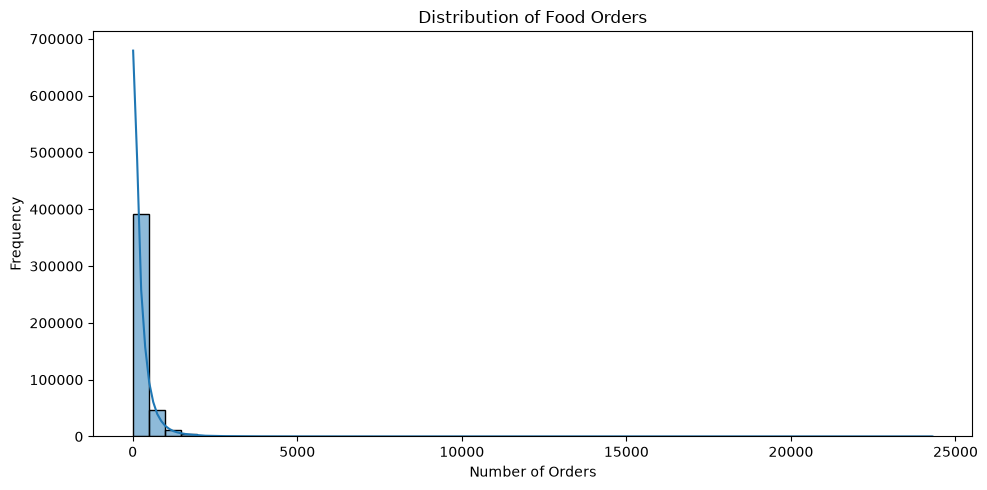

In [6]:

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="num_orders", bins=50, kde=True)

plt.title("Distribution of Food Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


week
1     271.136550
2     271.783149
3     239.828217
4     257.365524
5     419.263729
6     332.848911
7     334.455456
8     240.674085
9     253.413805
10    283.954180
Name: num_orders, dtype: float64


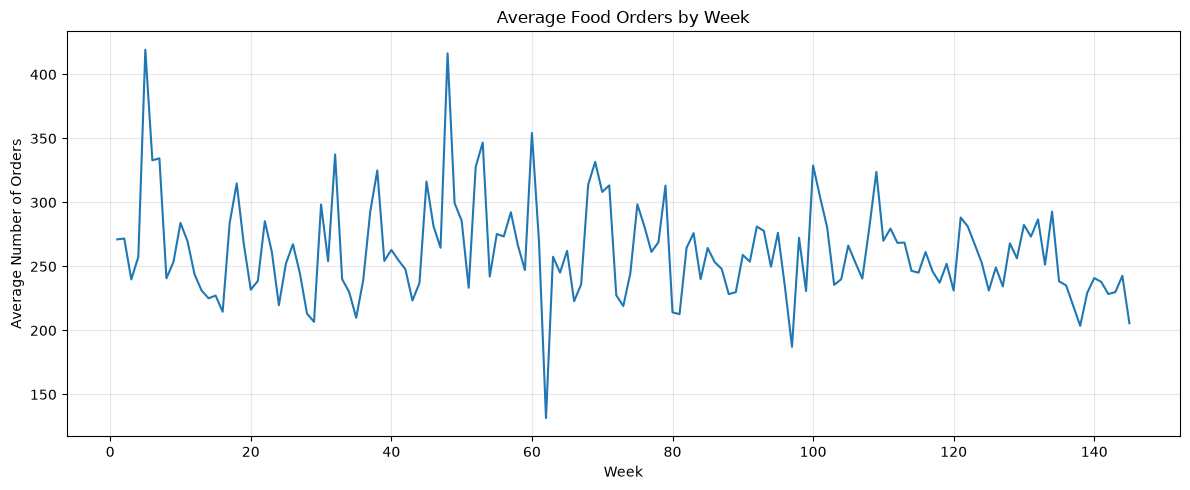

In [10]:

weekly_demand = df.groupby("week")["num_orders"].mean()

print(weekly_demand.head(10))

plt.figure(figsize=(12, 5))
weekly_demand.plot()

plt.title("Average Food Orders by Week")
plt.xlabel("Week")
plt.ylabel("Average Number of Orders")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


   meal_id   category cuisine  num_orders
0     1885  Beverages    Thai         177
1     1993  Beverages    Thai         270
2     2539  Beverages    Thai         189
3     2139  Beverages  Indian          54
4     2631  Beverages  Indian          40

Average demand by category:
category
Rice Bowl       624.822288
Sandwich        529.776276
Salad           383.218460
Beverages       316.526116
Extras          293.834169
Pizza           222.817309
Other Snacks    162.234691
Starters        155.276110
Seafood         100.895898
Fish             85.595268
Soup             82.023353
Desert           66.250905
Pasta            59.137142
Biryani          30.651402
Name: num_orders, dtype: float64


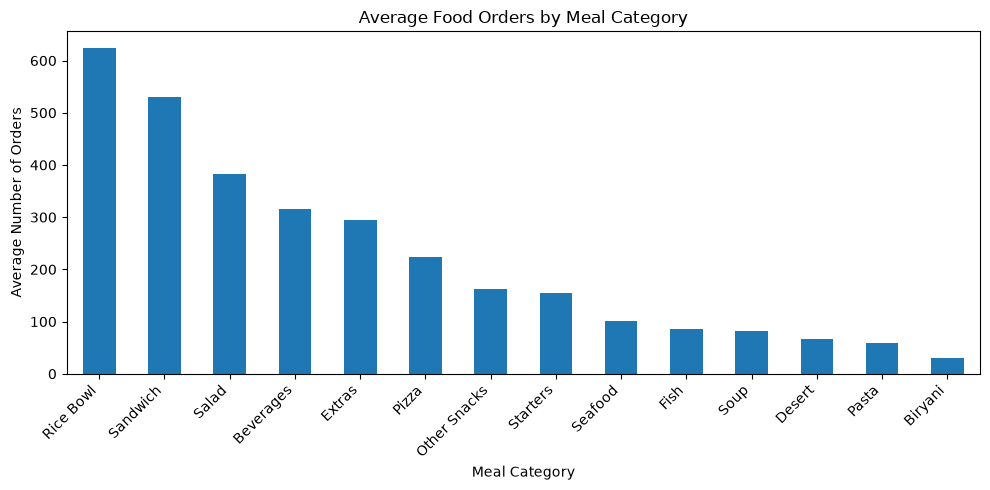

In [11]:

meal_info = pd.read_csv("../data/raw/meal_info.csv")

df_meals = df.merge(meal_info, on="meal_id", how="left")

print(df_meals[["meal_id", "category", "cuisine", "num_orders"]].head())

meal_demand = (
    df_meals.groupby("category")["num_orders"]
    .mean()
    .sort_values(ascending=False)
)

print("\nAverage demand by category:")
print(meal_demand)

meal_demand.plot(kind="bar", figsize=(10, 5))
plt.title("Average Food Orders by Meal Category")
plt.xlabel("Meal Category")
plt.ylabel("Average Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


center_id
13     609.784984
43     562.452511
10     481.969779
137    452.201625
52     446.994852
          ...    
161    145.581828
74     131.277356
149    126.972117
91     123.881119
41     121.807005
Name: num_orders, Length: 77, dtype: float64


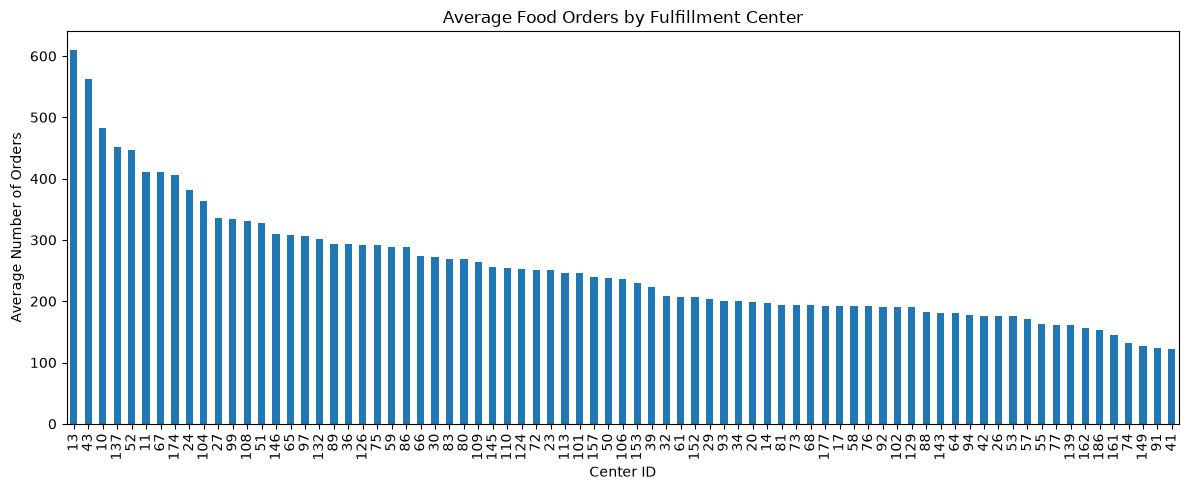

In [12]:

center_demand = (
    df.groupby("center_id")["num_orders"]
    .mean()
    .sort_values(ascending=False)
)

print(center_demand)

center_demand.plot(kind="bar", figsize=(12, 5))
plt.title("Average Food Orders by Fulfillment Center")
plt.xlabel("Center ID")
plt.ylabel("Average Number of Orders")
plt.tight_layout()
plt.show()


price_range
(2.107, 175.63]     410.884885
(175.63, 348.29]    313.433861
(348.29, 520.95]    136.528659
(520.95, 693.61]     99.191545
(693.61, 866.27]     50.288713
Name: num_orders, dtype: float64


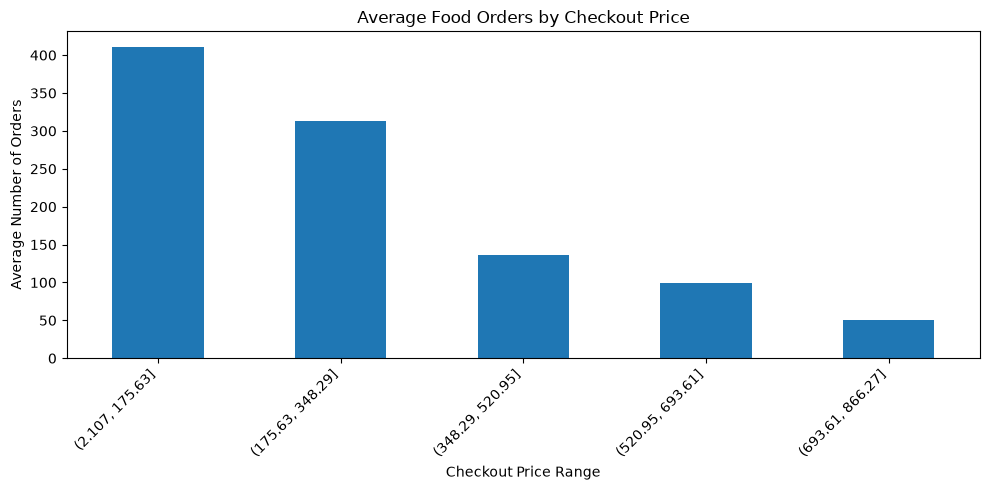

In [13]:

# Compare average orders across price ranges
df["price_range"] = pd.cut(
    df["checkout_price"],
    bins=5
)

price_demand = df.groupby(
    "price_range", observed=True
)["num_orders"].mean()

print(price_demand)

price_demand.plot(kind="bar", figsize=(10, 5))
plt.title("Average Food Orders by Checkout Price")
plt.xlabel("Checkout Price Range")
plt.ylabel("Average Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



Average orders by emailer_for_promotion:
                             mean   count
emailer_for_promotion                    
0                      229.262883  419498
1                      631.097544   37050


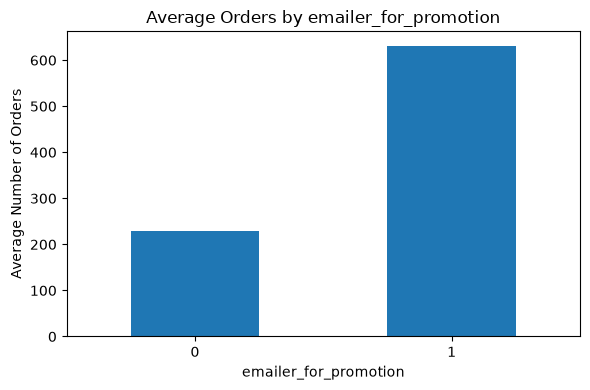


Average orders by homepage_featured:
                         mean   count
homepage_featured                    
0                  221.050040  406693
1                  594.884786   49855


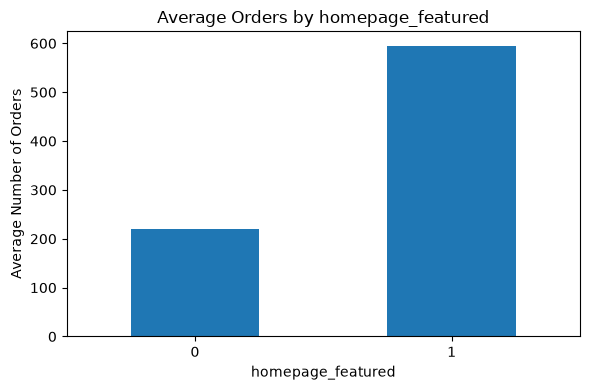

In [14]:

promotion_columns = [
    "emailer_for_promotion",
    "homepage_featured"
]

for column in promotion_columns:
    print(f"\nAverage orders by {column}:")
    print(df.groupby(column)["num_orders"].agg(["mean", "count"]))

    df.groupby(column)["num_orders"].mean().plot(
        kind="bar",
        figsize=(6, 4)
    )

    plt.title(f"Average Orders by {column}")
    plt.xlabel(column)
    plt.ylabel("Average Number of Orders")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


       checkout_price     base_price  discount_amount  discount_percentage  \
count   456548.000000  456548.000000    456548.000000        456548.000000   
mean       332.238933     354.156627        21.917695             5.719500   
std        152.939723     160.715914        48.495857            11.362753   
min          2.970000      55.350000      -185.300000           -72.789753   
25%        228.950000     243.500000        -1.000000            -0.145406   
50%        296.820000     310.460000         1.000000             0.141217   
75%        445.230000     458.870000        16.520000             6.242147   
max        866.270000     866.270000       561.600000            99.060870   

          num_orders  
count  456548.000000  
mean      261.872760  
std       395.922798  
min        13.000000  
25%        54.000000  
50%       136.000000  
75%       324.000000  
max     24299.000000  


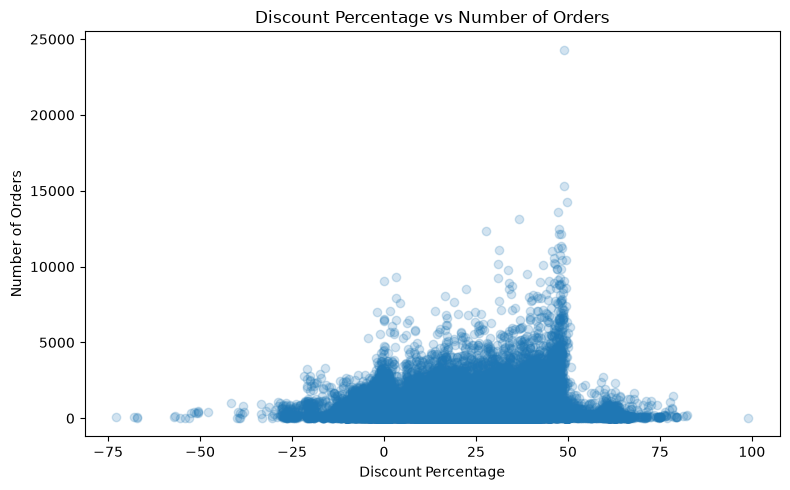

In [15]:

df["discount_amount"] = df["base_price"] - df["checkout_price"]

df["discount_percentage"] = (
    df["discount_amount"] / df["base_price"].replace(0, np.nan)
) * 100

print(df[
    ["checkout_price", "base_price", "discount_amount",
     "discount_percentage", "num_orders"]
].describe())

plt.figure(figsize=(8, 5))
plt.scatter(
    df["discount_percentage"],
    df["num_orders"],
    alpha=0.2
)

plt.title("Discount Percentage vs Number of Orders")
plt.xlabel("Discount Percentage")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


In [16]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check target variable
print("\nTarget variable statistics:")
print(df["num_orders"].describe())

# Check invalid values
print("\nNegative order counts:", (df["num_orders"] < 0).sum())
print("Zero order counts:", (df["num_orders"] == 0).sum())

# Check unique values
print("\nUnique weeks:", df["week"].nunique())
print("Unique centers:", df["center_id"].nunique())
print("Unique meals:", df["meal_id"].nunique())


Missing values:
id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
price_range              0
discount_amount          0
discount_percentage      0
dtype: int64

Duplicate rows: 0

Target variable statistics:
count    456548.000000
mean        261.872760
std         395.922798
min          13.000000
25%          54.000000
50%         136.000000
75%         324.000000
max       24299.000000
Name: num_orders, dtype: float64

Negative order counts: 0
Zero order counts: 0

Unique weeks: 145
Unique centers: 77
Unique meals: 51


In [17]:

print("EDA SUMMARY")
print("-" * 40)
print("Training rows:", len(df))
print("Features and columns:", len(df.columns))
print("Unique weeks:", df["week"].nunique())
print("Unique fulfillment centers:", df["center_id"].nunique())
print("Unique meals:", df["meal_id"].nunique())
print("Average orders:", round(df["num_orders"].mean(), 2))
print("Median orders:", df["num_orders"].median())
print("Maximum orders:", df["num_orders"].max())


EDA SUMMARY
----------------------------------------
Training rows: 456548
Features and columns: 12
Unique weeks: 145
Unique fulfillment centers: 77
Unique meals: 51
Average orders: 261.87
Median orders: 136.0
Maximum orders: 24299
